In [1]:
import stim
import qiskit
import surface_code as surf
import stim_to_qiskit as stimq
import run_on_hardware as hard
import build_emerald_qubit_rotated as emerald
from typing import Optional
import numpy as np

rounds   2: P_error = 0.43228 +- 0.00157
rounds   4: P_error = 0.47951 +- 0.00158
rounds   6: P_error = 0.49530 +- 0.00158
rounds   8: P_error = 0.49899 +- 0.00158
rounds  10: P_error = 0.50006 +- 0.00158
rounds  12: P_error = 0.50103 +- 0.00158
rounds  14: P_error = 0.49901 +- 0.00158
rounds  16: P_error = 0.50260 +- 0.00158
rounds  18: P_error = 0.50220 +- 0.00158
rounds  20: P_error = 0.50361 +- 0.00158
rounds  22: P_error = 0.50017 +- 0.00158
rounds  24: P_error = 0.50155 +- 0.00158
[Stim] eps_L = 0.31599 +- 0.00213   chi2/dof = 0.0/0


(0.31598913075581647,
 0.0021283655396311055,
 array([0.43228, 0.47951, 0.4953 , 0.49899, 0.50006, 0.50103, 0.49901,
        0.5026 , 0.5022 , 0.50361, 0.50017, 0.50155]),
 array([0.00156657, 0.00157981, 0.00158107, 0.00158114, 0.00158114,
        0.00158114, 0.00158114, 0.00158112, 0.00158112, 0.0015811 ,
        0.00158114, 0.00158113]))

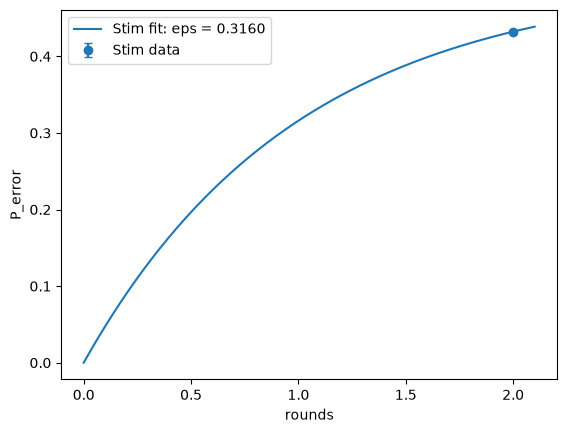

In [5]:
# Stim simulation logical error rate
# This function encodes the whole pipeline from stim.circuit creation
# to logical error rate fitting for a simulation
hard.logical_error_rate_stim(np.arange(2,25, 2), basis = "X")

In [ ]:
# Hardware simulation logical error rate
# This function encodes the whole pipeline from stim.circuit creation
# to logical error rate fitting for a IQM
hard.logical_error_rate_hardware(np.arange(2,10, 2), basis = "X")

/home/iceman/.local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/iceman/.local/lib/python3.13/site-packages/qiskit/compiler/transpiler.py:269: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  pm = generate_preset_pass_manager(


two-qubit gates: 48 -> 48 (an increase means SWAPs were inserted)
physical qubits used: [0, 1, 5, 12, 3, 4, 10, 11, 19, 20, 2, 8, 9, 17, 18, 26, 25]
job id: 01a2028a-06d1-70b4-9a89-75498742bb70


Progress in queue:  58%|████████████████████████████████████████████████████████████████████▎                                                | 7/12 [07:32<05:23, 64.62s/it]

rounds   2: shots   5000  decoded P_error = 0.1926 +- 0.0056   raw logical flips = 0.3138
rounds   4: shots   5000  decoded P_error = 0.3880 +- 0.0069   raw logical flips = 0.4670
rounds   6: shots   5000  decoded P_error = 0.4384 +- 0.0070   raw logical flips = 0.4820
rounds   8: shots   5000  decoded P_error = 0.4950 +- 0.0071   raw logical flips = 0.5106
[Hardware d=3] eps_L = 0.13145 +- 0.00251   chi2/dof = 74.8/2


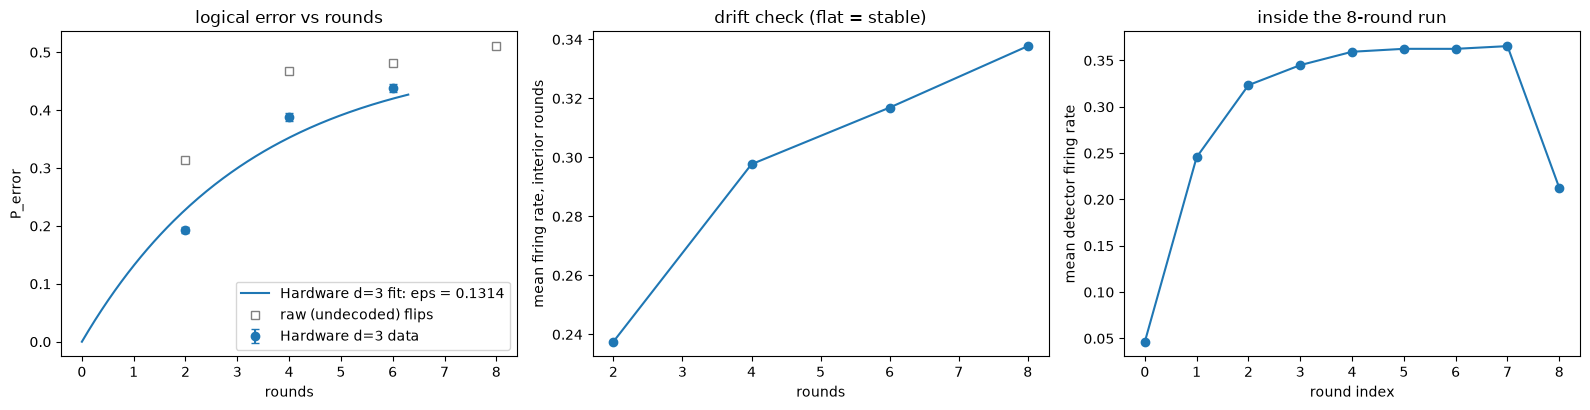

In [5]:
DEFAULT_NOISE = dict(
    after_clifford_depolarization  = 0.003,
    after_reset_flip_probability   = 0.003,
    before_measure_flip_probability= 0.003,
    before_round_data_depolarization = 0.003,
)

# analyzes the saved qiskit hardware runs
results = hard.analyse_saved_runs(
    save_prefix="syndromes", 
    distance=3, 
    noise=DEFAULT_NOISE, 
    label="Hardware d=3", 
    show_diagnostics=True
)